# 01 · Drift univariado por composição e por falta de dados

> Booster reconstruído com `scale_pos_weight=13.882494684620836`; corte de referência = 0,50. A suíte anterior permanece preservada.

**Objetivo.** Medir separadamente quanto a distribuição de cada entrada muda e como quatro métricas supervisionadas respondem: Brier, AUC ROC, área trapezoidal da curva precisão–recall (PR-AUC) e KS de discriminação. Recall e precisão a 0,50 são apenas diagnósticos. Não existe regra automática de aprovação, reprovação ou parada: todos os cenários da grade são avaliados.

**Etapas transferíveis:** (1) recuperar divisão rotulada e congelar o modelo; (2) calcular baseline; (3) fixar os bins de drift antes do stress; (4) construir trajetórias por variável e direção, mantendo a linha inteira na reponderação; (5) medir intensidade aplicada, PSI, ESS e quatro métricas; (6) desenhar curvas e calcular diferenças versus baseline; (7) repetir com falha artificial de medição; (8) interpretar junto ao mecanismo e à incerteza. `cs-test.csv` só oferece diagnóstico de entradas e scores porque não tem rótulo.

A reponderação de perfis observados representa uma hipótese de mudança de composição em que a relação condicional P(Y|X) é estável. Apagar valores de X com Y fixo representa, diferentemente, uma falha de medição: o risco real do mesmo cliente não mudou. Nenhum dos dois mecanismos é uma previsão do futuro.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 1.1 Preparação fiel ao notebook original

Os caminhos abaixo são as únicas configurações de ambiente. `Unnamed: 0` é um índice do CSV e não entra no modelo. Os valores ausentes originais são entregues diretamente ao XGBoost, sem imputação. Embora `enable_categorical=True` tenha sido usado no treino, as dez variáveis desta base são numéricas.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

P = DATA_DIR_PROJECT
DIR_DADOS = next((d for d in (P, P.parent) if (d / 'cs-training.csv').is_file()), None)
if DIR_DADOS is None:
    raise FileNotFoundError('Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.')
DIR_SAIDA = TABLES_DIR
ARQUIVO_MODELO = MODEL_DIR / 'model_class_retreinado.json'
DIR_SAIDA.mkdir(parents=True, exist_ok=True)
for arquivo in [DIR_DADOS / 'cs-training.csv', DIR_DADOS / 'cs-test.csv', ARQUIVO_MODELO]:
    if not arquivo.is_file():
        raise FileNotFoundError(f'Arquivo necessário não encontrado: {arquivo}')

FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines', 'age',
    'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
]
ALVO = 'SeriousDlqin2yrs'

bruto = pd.read_csv(DIR_DADOS / 'cs-training.csv').drop(columns='Unnamed: 0')
assert list(bruto.drop(columns=ALVO).columns) == FEATURES, 'Ordem ou nomes de features divergentes.'
X_total, y_total = bruto[FEATURES], bruto[ALVO].astype(int)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_total, y_total, test_size=0.15, random_state=33
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=33
)
assert (len(X_train), len(X_val), len(X_test)) == (104996, 22504, 22500)

modelo = xgb.Booster()
modelo.load_model(str(ARQUIVO_MODELO))
if modelo.feature_names is not None:
    assert modelo.feature_names == FEATURES, 'Features do Booster divergentes.'
# A mudança do dispositivo afeta somente a inferência, não as árvores treinadas.
modelo.set_param({'device': 'cpu'})

def prever(X):
    matriz = xgb.DMatrix(X[FEATURES], feature_names=FEATURES, enable_categorical=True)
    return np.asarray(modelo.predict(matriz), dtype=float)

y = y_test.to_numpy(dtype=int)
p = prever(X_test)
assert len(p) == len(y) and np.isfinite(p).all()
print(f'Treino={len(X_train):,} | Validação={len(X_val):,} | Holdout={len(X_test):,}')
print(f'Árvores disponíveis={modelo.num_boosted_rounds()} | Prevalência holdout={y.mean():.4%}')

Treino=104,996 | Validação=22,504 | Holdout=22,500
Árvores disponíveis=103 | Prevalência holdout=6.6667%


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1.2 Métricas e símbolos

Para rótulo $y_i\in\{0,1\}$, score $p_i\in[0,1]$ e peso não negativo $w_i$, calculamos **Brier** $\sum_i w_i(y_i-p_i)^2/\sum_iw_i$ (menor é melhor), **AUC ROC** como área sob TPR versus FPR (maior é melhor), **PR-AUC trapezoidal** como área geométrica sob precisão versus recall (maior é melhor) e **KS do modelo** $\max_t[TPR(t)-FPR(t)]$ em todos os cortes $t$ (maior é melhor). TPR é proporção de eventos capturados; FPR é proporção de não eventos sinalizados. A área PR-AUC é `auc(recall, precision)` de `precision_recall_curve`; **AP** usa soma em degraus e permanece coluna auxiliar, sem ser chamada de PR-AUC. Empates nos scores são agrupados pela biblioteca.

Precisão e recall em **0,50** descrevem uma decisão específica, sem entrar em regra de parada. O **PSI** mede mudança da distribuição da entrada em faixas fixas e não mede acerto. O **ESS** $(\sum_iw_i)^2/\sum_iw_i^2$ mostra a concentração dos pesos; ESS baixo exige cautela na interpretação, sem descartar automaticamente o cenário. `ks_modelo` mede separação entre classes; `ks_variavel` em outros cadernos mede distância entre distribuições de X e é outra grandeza.

In [4]:
from sklearn.metrics import precision_recall_curve, auc as area_curva, roc_curve

def metricas(y_true, probas, pesos=None, threshold=0.5):
    y_true = np.asarray(y_true, dtype=int)
    probas = np.asarray(probas, dtype=float)
    pesos = np.ones(len(y_true), dtype=float) if pesos is None else np.asarray(pesos, dtype=float)
    if not (len(y_true) == len(probas) == len(pesos)) or (pesos < 0).any() or pesos.sum() <= 0:
        raise ValueError('Dimensões ou pesos inválidos.')
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, probas, sample_weight=pesos)
    fpr_curve, tpr_curve, _ = roc_curve(y_true, probas, sample_weight=pesos)
    pred = probas >= threshold
    tp = pesos[(y_true == 1) & pred].sum()
    fp = pesos[(y_true == 0) & pred].sum()
    tn = pesos[(y_true == 0) & ~pred].sum()
    fn = pesos[(y_true == 1) & ~pred].sum()
    prev = np.average(y_true, weights=pesos)
    ap = average_precision_score(y_true, probas, sample_weight=pesos)
    return {
        'auc': roc_auc_score(y_true, probas, sample_weight=pesos),
        'prauc_trap': area_curva(recall_curve, precision_curve),
        'ks_modelo': float(np.max(tpr_curve - fpr_curve)),
        'brier': brier_score_loss(y_true, probas, sample_weight=pesos),
        'ap': ap, 'ap_lift': ap / prev,
        'recall': tp / (tp + fn),
        'precision': tp / (tp + fp) if tp + fp else np.nan,
        'fpr': fp / (fp + tn),
        'prevalencia': prev,
        'ess': pesos.sum() ** 2 / np.square(pesos).sum(),
        'ess_frac': pesos.sum() ** 2 / np.square(pesos).sum() / len(pesos),
    }

base = metricas(y, p)
display(pd.DataFrame([base], index=['Holdout original']).round(5))
assert np.isclose(base['auc'], _manifesto_versao['baseline_holdout']['auc_roc'], atol=1e-7, rtol=0)
assert np.isclose(base['ap'], _manifesto_versao['baseline_holdout']['ap'], atol=1e-7, rtol=0)
assert np.isclose(base['brier'], _manifesto_versao['baseline_holdout']['brier'], atol=1e-7, rtol=0)

,auc,prauc_trap,ks_modelo,brier,ap,ap_lift,recall,precision,fpr,prevalencia,ess,ess_frac
Holdout original,0.86684,0.39599,0.58771,0.14404,0.39639,5.94578,0.794,0.21525,0.20676,0.06667,22500.0,1.0


## 2. Medida univariada de drift

O PSI é calculado em bins definidos **uma vez no holdout sem stress**. Para valores com poucas categorias numéricas, separamos valores; para variáveis contínuas, usamos até dez faixas por quantis. Valores ausentes têm um bin próprio. Para proporções $q$ (cenário) e $r$ (referência), $PSI=\sum_b(q_b-r_b)\ln(q_b/r_b)$, com suavização numérica apenas para bins vazios. Isto fornece zero exato no cenário original. PSI é uma medida de distribuição e **não** mede perda de desempenho por si só.

In [5]:
def cortes_referencia(referencia):
    v = np.asarray(referencia, dtype=float)
    v = v[np.isfinite(v)]
    unicos = np.unique(v)
    if len(unicos) <= 12:
        return (unicos[:-1] + (unicos[1:] - unicos[:-1]) / 2).astype(float)
    return np.unique(np.quantile(v, np.linspace(0, 1, 11)[1:-1])).astype(float)

def proporcoes_bins(valores, cortes, pesos=None):
    v = np.asarray(valores, dtype=float)
    w = np.ones(len(v), dtype=float) if pesos is None else np.asarray(pesos, dtype=float)
    finito = np.isfinite(v)
    indice = np.full(len(v), len(cortes) + 1, dtype=int)
    indice[finito] = np.digitize(v[finito], cortes, right=True)
    contagem = np.bincount(indice, weights=w, minlength=len(cortes) + 2)
    return contagem / contagem.sum()

def psi(referencia, cenario, pesos=None):
    cortes = cortes_referencia(referencia)
    r = proporcoes_bins(referencia, cortes)
    q = proporcoes_bins(cenario, cortes, pesos)
    eps = 1e-8
    return float(np.sum((q - r) * np.log((q + eps) / (r + eps))))

assert max(abs(psi(X_test[f], X_test[f])) for f in FEATURES) < 1e-12
print('PSI zero verificado para as dez variáveis no cenário original.')

PSI zero verificado para as dez variáveis no cenário original.


## 3. Stress por reponderação de linhas intactas

Para cada variável, atribuímos ao valor observado seu posto percentílico $u_i$ dentro do holdout. A direção **cauda alta** usa $w_i(s)\propto\exp[s(2u_i-1)]$; a **cauda baixa** usa o sinal inverso. A força $s$ percorre a grade abaixo. Os pesos de observações presentes são normalizados para média 1; observações originalmente ausentes mantêm peso 1. Assim a taxa de ausência da variável alvo do stress permanece constante.

O peso é aplicado à **linha inteira**. Por exemplo, ao enriquecer idades altas, outras variáveis correlacionadas podem mudar juntamente. Isso é parte de um deslocamento de população plausível, não uma edição sintética e isolada da idade. Correlação e rótulo da linha permanecem observados. As curvas não identificam necessariamente o efeito causal de uma única variável.

In [6]:
INTENSIDADES = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8, 10]

def pesos_cauda(coluna, intensidade, direcao):
    x = pd.Series(coluna).reset_index(drop=True)
    observado = x.notna().to_numpy()
    w = np.ones(len(x), dtype=float)
    percentil = x[observado].rank(method='average', pct=True).to_numpy()
    sinal = 1 if direcao == 'alta' else -1
    expoente = intensidade * sinal * (2 * percentil - 1)
    expoente -= expoente.max()  # estabilidade numérica; a normalização cancela esta constante
    w_obs = np.exp(expoente)
    w[observado] = w_obs / w_obs.mean()
    return w

linhas = []
for variavel in FEATURES:
    for direcao in ['baixa', 'alta']:
        for s in INTENSIDADES:
            w = pesos_cauda(X_test[variavel], s, direcao)
            m = metricas(y, p, w)
            linhas.append({
                'familia': 'reponderacao_univariada', 'variavel': variavel,
                'direcao': direcao, 'intensidade': s, 'fracao_nova_ausencia': np.nan,
                'psi_variavel': psi(X_test[variavel], X_test[variavel], w),
                'media_variavel': np.average(
                    X_test[variavel].dropna(), weights=w[X_test[variavel].notna().to_numpy()]
                ),
                **m,
            })

resultados_ponderacao = pd.DataFrame(linhas)
for metrica in ['auc', 'prauc_trap', 'ks_modelo', 'brier', 'ap', 'ap_lift', 'recall', 'precision', 'fpr', 'prevalencia']:
    resultados_ponderacao[f'delta_{metrica}'] = resultados_ponderacao[metrica] - base[metrica]
assert np.allclose(resultados_ponderacao.query('intensidade == 0')['psi_variavel'], 0)
assert np.allclose(resultados_ponderacao.query('intensidade == 0')['ess_frac'], 1)
display(resultados_ponderacao.query('intensidade in [0, 2, 6, 10]')[
    ['variavel', 'direcao', 'intensidade', 'psi_variavel', 'ess_frac', 'auc', 'prauc_trap', 'ks_modelo', 'brier', 'ap', 'recall', 'precision', 'fpr', 'prevalencia']
].round(4))

,variavel,direcao,intensidade,psi_variavel,ess_frac,auc,prauc_trap,ks_modelo,brier,ap,recall,precision,fpr,prevalencia
0,RevolvingUtilizationOfUnsecuredLines,baixa,0.0,0.0000,1.0000,0.8668,0.3960,0.5877,0.1440,0.3964,0.7940,0.2153,0.2068,0.0667
6,RevolvingUtilizationOfUnsecuredLines,baixa,2.0,1.0603,0.4842,0.8423,0.2637,0.5597,0.0648,0.2646,0.5721,0.1957,0.0644,0.0266
9,RevolvingUtilizationOfUnsecuredLines,baixa,6.0,4.8590,0.1781,0.8359,0.2714,0.5588,0.0544,0.2804,0.5321,0.2109,0.0479,0.0235
11,RevolvingUtilizationOfUnsecuredLines,baixa,10.0,8.5447,0.1200,0.8421,0.2971,0.5778,0.0591,0.3080,0.5582,0.2194,0.0541,0.0265
12,RevolvingUtilizationOfUnsecuredLines,alta,0.0,0.0000,1.0000,0.8668,0.3960,0.5877,0.1440,0.3964,0.7940,0.2153,0.2068,0.0667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
227,NumberOfDependents,baixa,10.0,3.9182,0.6023,0.8708,0.3913,0.5981,0.1290,0.3918,0.7729,0.2165,0.1806,0.0607
228,NumberOfDependents,alta,0.0,0.0000,1.0000,0.8668,0.3960,0.5877,0.1440,0.3964,0.7940,0.2153,0.2068,0.0667
234,NumberOfDependents,alta,2.0,1.0182,0.4691,0.8695,0.4238,0.5940,0.1624,0.4245,0.8329,0.2202,0.2412,0.0756
237,NumberOfDependents,alta,6.0,4.8411,0.1665,0.8787,0.4655,0.6118,0.1717,0.4669,0.8648,0.2311,0.2609,0.0831


## 3.1 Trajetórias completas, sem fronteira automática

A intensidade $s$ da reponderação exponencial é um parâmetro do mecanismo, **não uma porcentagem de mudança da variável**. Registramos seu efeito realizado no PSI e no ESS. Em cada variável/direção, mostramos a amplitude observada de Brier, AUC, PR-AUC e KS e suas diferenças em relação ao holdout original. A curva pode subir, cair ou mudar de sentido; um único número não descreveria essas respostas. A grade é finita e exploratória.

In [7]:
CAMPOS_CENTRAIS = ['brier', 'auc', 'prauc_trap', 'ks_modelo']
resumo_trajetorias = (resultados_ponderacao.groupby(['variavel','direcao'], as_index=False)
    .agg(intensidade_max=('intensidade','max'), psi_min=('psi_variavel','min'),
         psi_max=('psi_variavel','max'), ess_frac_min=('ess_frac','min'),
         brier_min=('brier','min'), brier_max=('brier','max'),
         auc_min=('auc','min'), auc_max=('auc','max'),
         prauc_trap_min=('prauc_trap','min'), prauc_trap_max=('prauc_trap','max'),
         ks_modelo_min=('ks_modelo','min'), ks_modelo_max=('ks_modelo','max')))
for campo in CAMPOS_CENTRAIS:
    resumo_trajetorias[f'maior_queda_{campo}'] = resultados_ponderacao.groupby(['variavel','direcao'])[f'delta_{campo}'].min().to_numpy()
    resumo_trajetorias[f'maior_alta_{campo}'] = resultados_ponderacao.groupby(['variavel','direcao'])[f'delta_{campo}'].max().to_numpy()
display(resumo_trajetorias.round(5))

,variavel,direcao,intensidade_max,psi_min,psi_max,ess_frac_min,brier_min,brier_max,auc_min,auc_max,prauc_trap_min,prauc_trap_max,ks_modelo_min,ks_modelo_max,maior_queda_brier,maior_alta_brier,maior_queda_auc,maior_alta_auc,maior_queda_prauc_trap,maior_alta_prauc_trap,maior_queda_ks_modelo,maior_alta_ks_modelo
0,DebtRatio,alta,10.0,0.0,8.61928,0.10000,0.11975,0.14614,0.84670,0.86973,0.39599,0.42777,0.56121,0.59755,-0.02429,0.00211,-0.02014,0.00289,0.00000,0.03178,-0.02651,0.00984
1,DebtRatio,baixa,10.0,0.0,8.61169,0.10270,0.12518,0.14404,0.86684,0.90150,0.39421,0.41227,0.58771,0.68653,-0.01886,0.00000,0.00000,0.03466,-0.00179,0.01628,0.00000,0.09882
2,MonthlyIncome,alta,10.0,0.0,6.91433,0.12153,0.11176,0.14404,0.85610,0.86762,0.34497,0.39599,0.58268,0.58984,-0.03227,0.00000,-0.01074,0.00078,-0.05102,0.00000,-0.00504,0.00213
3,MonthlyIncome,baixa,10.0,0.0,6.90276,0.12209,0.14404,0.16780,0.84126,0.86684,0.34335,0.40224,0.55040,0.58771,0.00000,0.02376,-0.02558,0.00000,-0.05264,0.00625,-0.03731,0.00000
4,NumberOfDependents,alta,10.0,0.0,8.70472,0.09873,0.14404,0.17397,0.86675,0.88073,0.39599,0.48314,0.58771,0.61374,0.00000,0.02993,-0.00009,0.01389,0.00000,0.08715,0.00000,0.02603
5,NumberOfDependents,baixa,10.0,0.0,3.91820,0.60227,0.12896,0.14404,0.86684,0.87082,0.38967,0.39599,0.58762,0.59806,-0.01508,0.00000,0.00000,0.00398,-0.00632,0.00000,-0.00009,0.01035
6,NumberOfOpenCreditLinesAndLoans,alta,10.0,0.0,8.69184,0.09959,0.14400,0.17141,0.81557,0.86684,0.31486,0.39599,0.51717,0.58771,-0.00004,0.02737,-0.05127,0.00000,-0.08113,0.00000,-0.07055,0.00000
7,NumberOfOpenCreditLinesAndLoans,baixa,10.0,0.0,8.47620,0.10030,0.14404,0.25450,0.84061,0.88569,0.39599,0.44945,0.52960,0.62385,0.00000,0.11046,-0.02623,0.01885,0.00000,0.05346,-0.05812,0.03613
8,NumberOfTime30-59DaysPastDueNotWorse,alta,10.0,0.0,9.06523,0.08873,0.14404,0.39756,0.77118,0.86970,0.39599,0.57334,0.42215,0.59042,0.00000,0.25352,-0.09566,0.00286,0.00000,0.17735,-0.16557,0.00271
9,NumberOfTime30-59DaysPastDueNotWorse,baixa,10.0,0.0,1.62817,0.83669,0.10270,0.14404,0.83583,0.86684,0.25529,0.39599,0.53678,0.58771,-0.04134,0.00000,-0.03101,0.00000,-0.14070,0.00000,-0.05094,0.00000


## 3.2 Incerteza amostral em cenários previamente escolhidos

Para demonstrar a incerteza sem escolher os piores resultados pelo mesmo Y, fixamos antes de olhar o resultado as **cinco primeiras variáveis na ordem do modelo**, cauda alta e força $s=2$. Em 100 réplicas, reamostramos os mesmos índices do holdout para baseline e cenário (bootstrap pareado). Reportamos intervalos percentílicos 2,5%–97,5% dos deltas das quatro métricas. Esses intervalos condicionam ao modelo treinado, aos pesos escolhidos e ao holdout; não cobrem deriva futura nem incerteza do treino. Com muitos cenários exploratórios, não são inferência simultânea.

In [8]:
N_BOOTSTRAP = 100
cenarios_boot = [(f, 'alta', 2.0) for f in FEATURES[:5]]
aleatorio_boot = np.random.default_rng(3302)
linhas_boot = []
for variavel, direcao, s in cenarios_boot:
    w = pesos_cauda(X_test[variavel], s, direcao)
    observado = resultados_ponderacao.query('variavel == @variavel and direcao == @direcao and intensidade == @s').iloc[0]
    deltas = {campo: [] for campo in CAMPOS_CENTRAIS}
    for _ in range(N_BOOTSTRAP):
        idx = aleatorio_boot.integers(0, len(y), size=len(y))
        mb = metricas(y[idx], p[idx])
        ms = metricas(y[idx], p[idx], w[idx])
        for campo in deltas:
            deltas[campo].append(ms[campo] - mb[campo])
    for campo, amostras in deltas.items():
        li, ls = np.quantile(amostras, [.025, .975])
        linhas_boot.append({'variavel': variavel, 'direcao': direcao, 'intensidade': s,
            'metrica': campo, 'delta_observado': observado[campo] - base[campo],
            'ic95_delta_inferior': li, 'ic95_delta_superior': ls})
incerteza = pd.DataFrame(linhas_boot)
display(incerteza.round(5))

,variavel,direcao,intensidade,metrica,delta_observado,ic95_delta_inferior,ic95_delta_superior
0,RevolvingUtilizationOfUnsecuredLines,alta,2.0,brier,0.11879,0.11497,0.12158
1,RevolvingUtilizationOfUnsecuredLines,alta,2.0,auc,-0.03431,-0.04321,-0.02518
2,RevolvingUtilizationOfUnsecuredLines,alta,2.0,prauc_trap,0.07849,0.06898,0.09204
3,RevolvingUtilizationOfUnsecuredLines,alta,2.0,ks_modelo,-0.06783,-0.08994,-0.04906
4,age,alta,2.0,brier,-0.05634,-0.05834,-0.05414
5,age,alta,2.0,auc,0.00836,-0.00765,0.02197
6,age,alta,2.0,prauc_trap,-0.05298,-0.08546,-0.02189
7,age,alta,2.0,ks_modelo,0.03803,0.00476,0.06585
8,NumberOfTime30-59DaysPastDueNotWorse,alta,2.0,brier,0.11383,0.10911,0.11806
9,NumberOfTime30-59DaysPastDueNotWorse,alta,2.0,auc,-0.01897,-0.02702,-0.01091


## 3.3 Visualizações da evolução

O mapa compara a **maior magnitude de mudança observada** de cada métrica em cada trajetória, sem classificar cenários. O gráfico seguinte coloca PSI da entrada no eixo horizontal e desempenho no vertical. Linha pontilhada é o baseline; linhas contínuas favorecem a cauda alta e tracejadas a baixa. PSI semelhante pode corresponder a impactos distintos. Consulte ESS antes de interpretar pontos extremos.

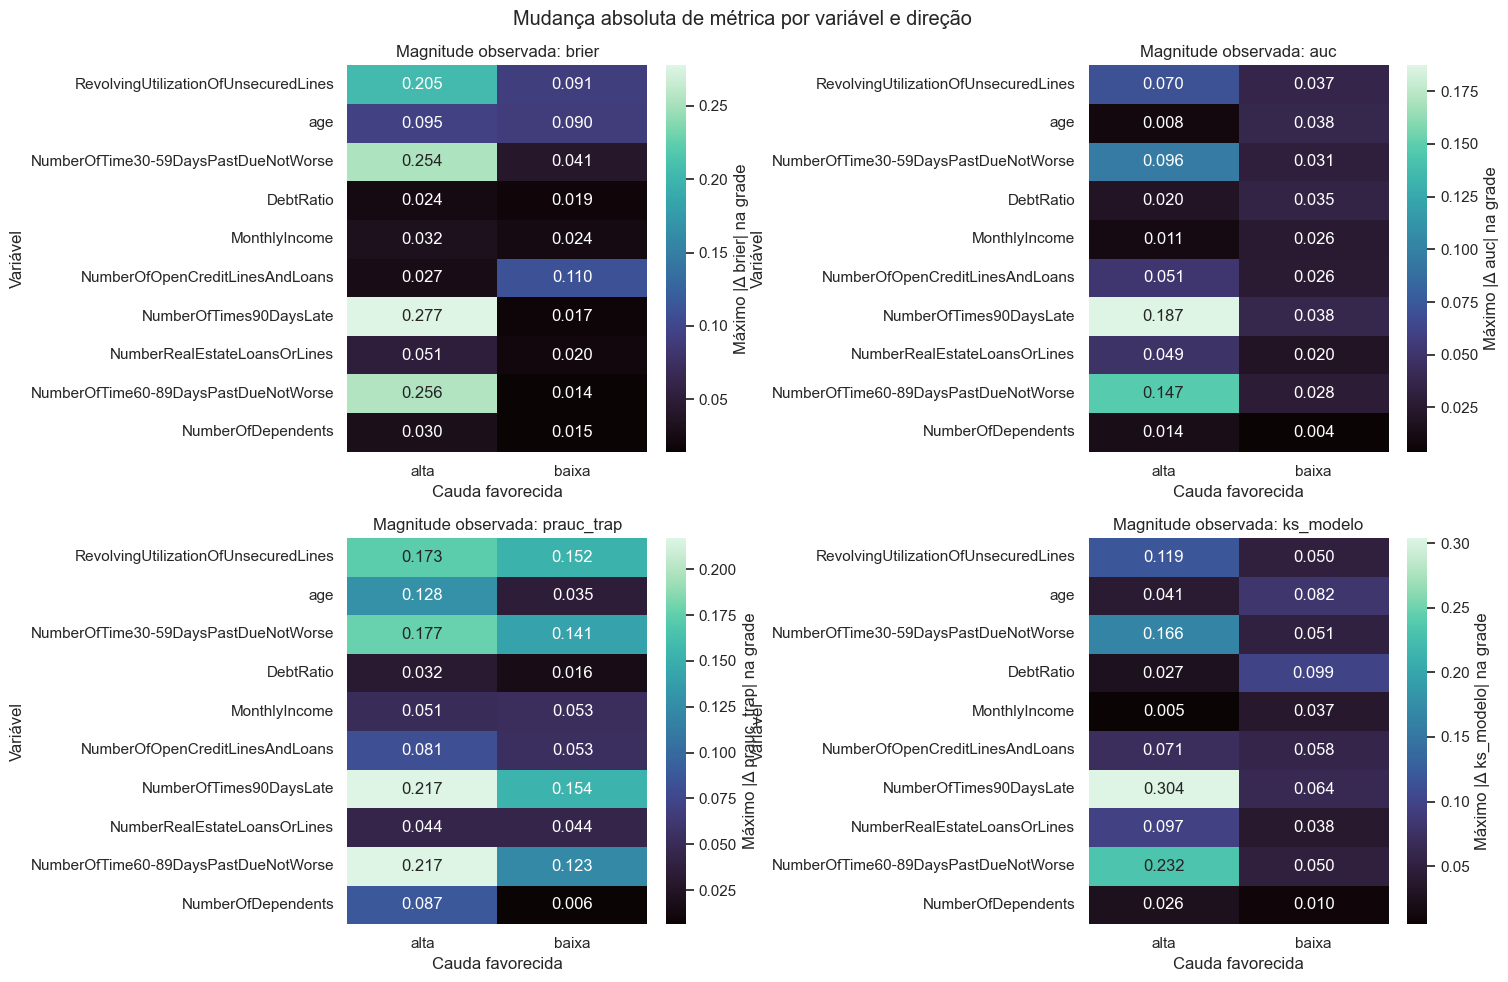

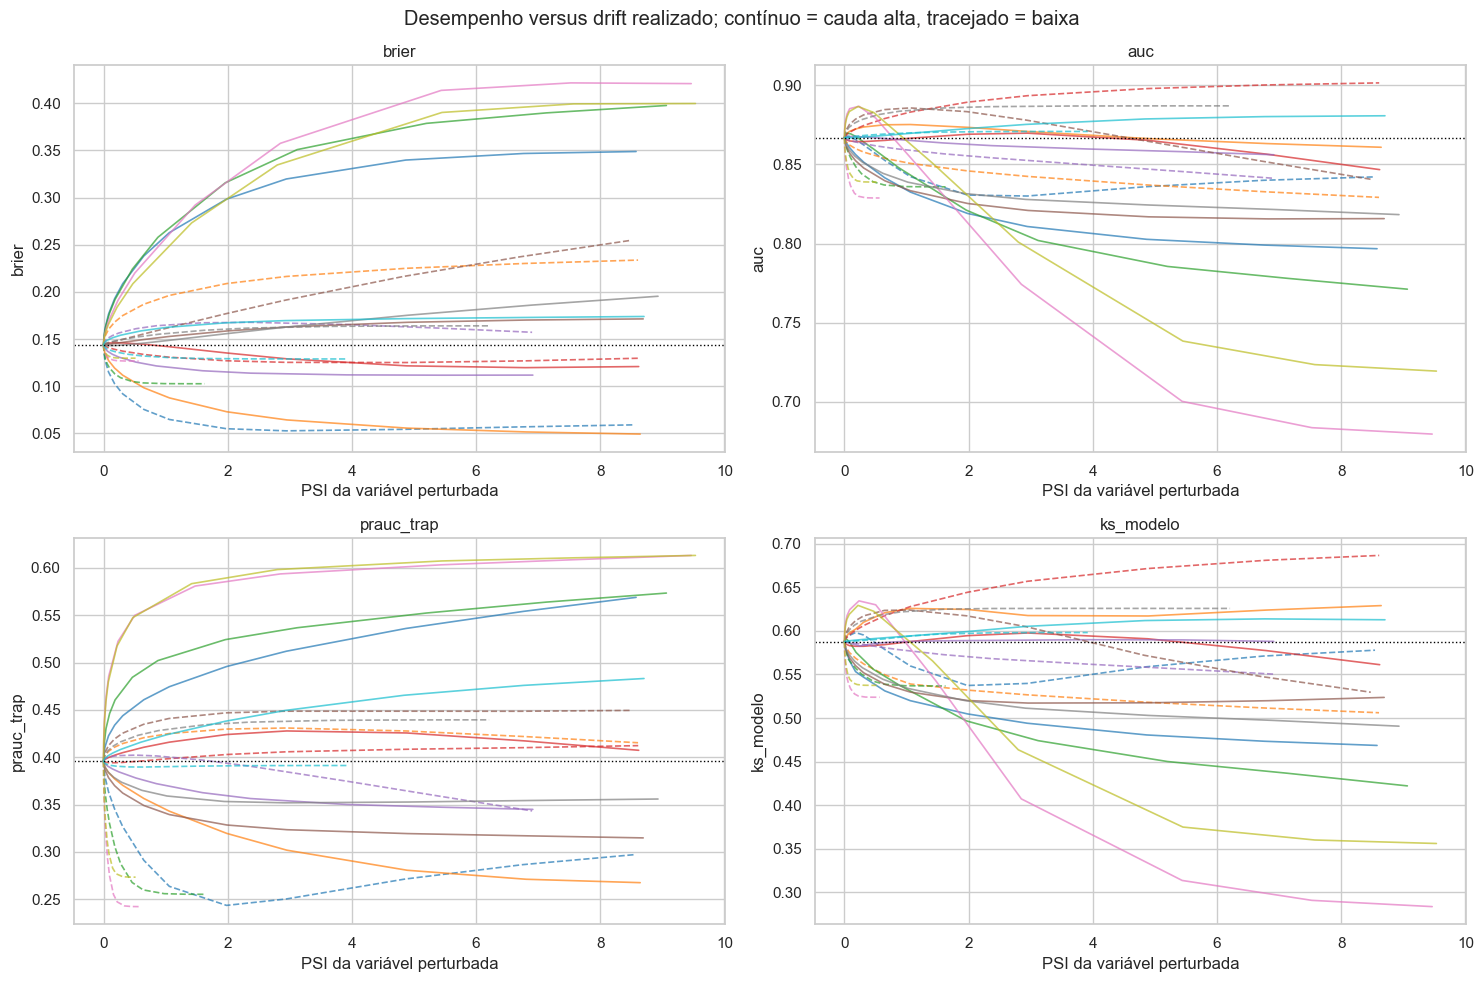

In [9]:
fig, eixos = plt.subplots(2, 2, figsize=(15, 10))
for ax, campo in zip(eixos.flat, CAMPOS_CENTRAIS):
    magnitude = resultados_ponderacao.groupby(['variavel','direcao'])[f'delta_{campo}'].apply(lambda s: s.abs().max()).unstack()
    sns.heatmap(magnitude.reindex(FEATURES), cmap='mako', annot=True, fmt='.3f',
                cbar_kws={'label':f'Máximo |Δ {campo}| na grade'}, ax=ax)
    ax.set(title=f'Magnitude observada: {campo}', xlabel='Cauda favorecida', ylabel='Variável')
fig.suptitle('Mudança absoluta de métrica por variável e direção')
plt.tight_layout(); plt.show()

fig, eixos = plt.subplots(2, 2, figsize=(15, 10))
cores = dict(zip(FEATURES, sns.color_palette('tab10', len(FEATURES))))
for ax, campo in zip(eixos.flat, CAMPOS_CENTRAIS):
    for (variavel, direcao), g in resultados_ponderacao.groupby(['variavel','direcao'], sort=False):
        g = g.sort_values('psi_variavel')
        ax.plot(g['psi_variavel'], g[campo], color=cores[variavel],
                ls='-' if direcao == 'alta' else '--', alpha=.7, lw=1.2)
    ax.axhline(base[campo], color='black', ls=':', lw=1)
    ax.set(title=campo, xlabel='PSI da variável perturbada', ylabel=campo)
fig.suptitle('Desempenho versus drift realizado; contínuo = cauda alta, tracejado = baixa')
plt.tight_layout(); plt.show()

## 4. Stress distinto: ausência artificial, individual e conjunta

Introduzimos faltantes em `MonthlyIncome`, `NumberOfDependents`, `DebtRatio` e `RevolvingUtilizationOfUnsecuredLines`. Primeiro apagamos valores de **uma variável por vez**; depois apagamos valores das **quatro simultaneamente** como comparação. Em cada nível, uma fração dos valores originalmente presentes é apagada. Sorteios fixos por linha e variável produzem cenários aninhados: o nível de 20% inclui os valores apagados no de 10%. Os faltantes que já existiam são mantidos. Rótulos e demais valores continuam iguais. O modelo é avaliado novamente em cada cenário, sem reentreino.

Esta falha de dados introduz combinações de `NaN` que podem não seguir o mecanismo real de ausência. A curva mostra sensibilidade ao cenário simulado, não uma previsão da frequência de falhas em produção. O PSI da ausência pode ficar muito alto porque um bin antes vazio passa a receber muitos registros; **não é comparável diretamente ao PSI da reponderação de população**. Avaliamos todas as frações; não há regra de parada ou de aprovação.

,familia,variavel,fracao_nova_ausencia,fracao_linhas_atingidas,psi_variavel,auc,prauc_trap,ks_modelo,brier,recall,precision
0,qualidade_ausencia_univariada,MonthlyIncome,0.0,0.00000,0.00000,0.86684,0.39599,0.58771,0.14404,0.79400,0.21525
2,qualidade_ausencia_univariada,MonthlyIncome,0.1,0.07853,0.03454,0.86663,0.39574,0.58590,0.14342,0.79200,0.21526
4,qualidade_ausencia_univariada,MonthlyIncome,0.2,0.15929,0.12977,0.86680,0.39553,0.58557,0.14266,0.79067,0.21575
6,qualidade_ausencia_univariada,MonthlyIncome,0.3,0.24022,0.27716,0.86670,0.39508,0.58548,0.14202,0.79000,0.21604
8,qualidade_ausencia_univariada,MonthlyIncome,0.4,0.32289,0.47976,0.86670,0.39473,0.58348,0.14139,0.78667,0.21490
10,qualidade_ausencia_univariada,MonthlyIncome,0.5,0.40244,0.72799,0.86636,0.39491,0.58171,0.14084,0.78467,0.21470
11,qualidade_ausencia_univariada,NumberOfDependents,0.0,0.00000,0.00000,0.86684,0.39599,0.58771,0.14404,0.79400,0.21525
13,qualidade_ausencia_univariada,NumberOfDependents,0.1,0.09676,0.15694,0.86681,0.39562,0.58757,0.14433,0.79400,0.21459
15,qualidade_ausencia_univariada,NumberOfDependents,0.2,0.19418,0.45046,0.86669,0.39556,0.58667,0.14466,0.79333,0.21357
17,qualidade_ausencia_univariada,NumberOfDependents,0.3,0.29316,0.82826,0.86661,0.39557,0.58567,0.14508,0.79333,0.21239


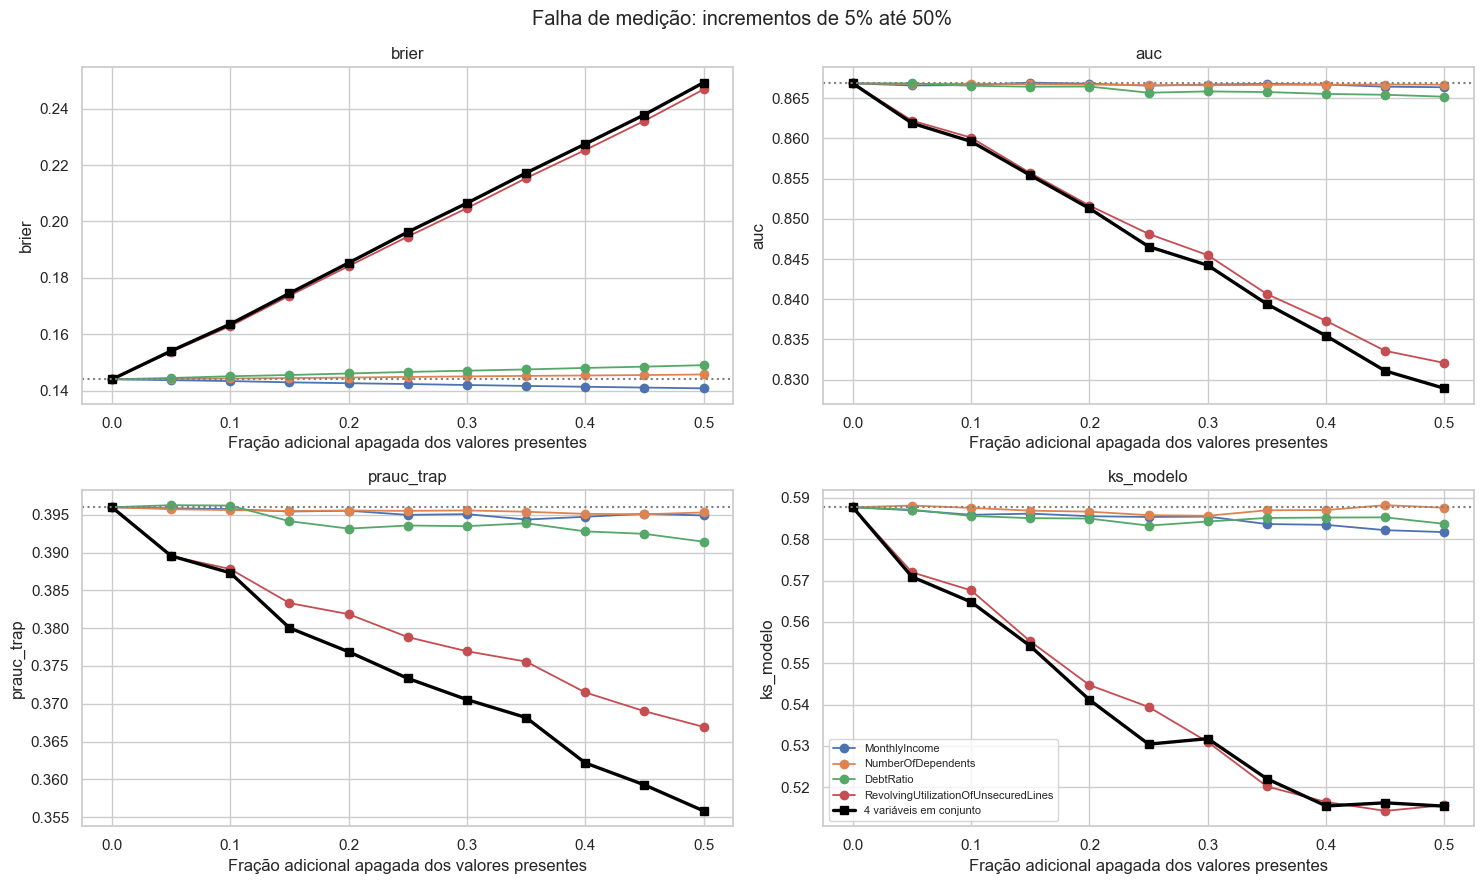

In [10]:
VARIAVEIS_AUSENCIA = [
    'MonthlyIncome', 'NumberOfDependents', 'DebtRatio',
    'RevolvingUtilizationOfUnsecuredLines',
]
FRACOES_AUSENCIA = np.round(np.arange(0, .501, .05), 2).tolist()
gerador = np.random.default_rng(3301)
sorteios = {f: gerador.random(len(X_test)) for f in VARIAVEIS_AUSENCIA}

linhas_ausencia = []
for variavel in VARIAVEIS_AUSENCIA + ['4 variáveis em conjunto']:
    ativas = VARIAVEIS_AUSENCIA if variavel == '4 variáveis em conjunto' else [variavel]
    familia = ('qualidade_ausencia_4_variaveis' if len(ativas) == 4
               else 'qualidade_ausencia_univariada')
    for fracao in FRACOES_AUSENCIA:
        X_corrompido = X_test.copy()
        mascara_apagada = np.zeros(len(X_test), dtype=bool)
        for f in ativas:
            apagar = X_test[f].notna().to_numpy() & (sorteios[f] < fracao)
            X_corrompido.loc[apagar, f] = np.nan
            mascara_apagada |= apagar
        p_corrompido = prever(X_corrompido)
        m = metricas(y, p_corrompido)
        psis = {f: psi(X_test[f], X_corrompido[f]) for f in ativas}
        linhas_ausencia.append({
            'familia': familia,
            'variavel': variavel,
            'direcao': 'ausencia',
            'intensidade': np.nan,
            'fracao_nova_ausencia': fracao,
            'psi_variavel': max(psis.values()),
            'psi_max_4_variaveis': max(psis.values()) if len(ativas) == 4 else np.nan,
            'fracao_linhas_atingidas': mascara_apagada.mean(),
            **{f'ausencia_{f}': X_corrompido[f].isna().mean() for f in VARIAVEIS_AUSENCIA},
            **m,
        })

resultados_ausencia = pd.DataFrame(linhas_ausencia)
for metrica in ['auc', 'prauc_trap', 'ks_modelo', 'brier', 'ap', 'ap_lift', 'recall', 'precision', 'fpr', 'prevalencia']:
    resultados_ausencia[f'delta_{metrica}'] = resultados_ausencia[metrica] - base[metrica]
display(resultados_ausencia.loc[resultados_ausencia.fracao_nova_ausencia.isin([0,.1,.2,.3,.4,.5]),
    ['familia','variavel','fracao_nova_ausencia','fracao_linhas_atingidas','psi_variavel',
     'auc','prauc_trap','ks_modelo','brier','recall','precision']].round(5))
fig, eixos = plt.subplots(2, 2, figsize=(15, 9))
for variavel, g in resultados_ausencia.groupby('variavel', sort=False):
    estilo = {'lw':2.4,'color':'black','marker':'s'} if variavel == '4 variáveis em conjunto' else {'lw':1.3,'marker':'o'}
    for ax, campo in zip(eixos.flat, CAMPOS_CENTRAIS):
        ax.plot(g['fracao_nova_ausencia'], g[campo], label=variavel, **estilo)
for ax, campo in zip(eixos.flat, CAMPOS_CENTRAIS):
    ax.axhline(base[campo], color='gray', ls=':')
    ax.set(xlabel='Fração adicional apagada dos valores presentes', ylabel=campo, title=campo)
eixos[1,1].legend(fontsize=8)
fig.suptitle('Falha de medição: incrementos de 5% até 50%')
plt.tight_layout(); plt.show()

## 5. Diagnóstico observável de `cs-test.csv`

Aqui comparamos as distribuições de `cs-test.csv` com as do **treino original**. Também comparamos a distribuição de scores prevista para `cs-test.csv` com a do holdout. Nenhuma métrica que dependa do alvo pode ser calculada para `cs-test.csv`, pois seus 101.503 rótulos estão vazios. PSI alto ou baixo, isoladamente, não prova alteração na relação entre variáveis e inadimplência.

,variavel,psi_treino_vs_cs_test,ausencia_treino,ausencia_cs_test
8,NumberOfTime60-89DaysPastDueNotWorse,0.0003,0.0000,0.0000
4,MonthlyIncome,0.0002,0.1990,0.1981
9,NumberOfDependents,0.0002,0.0264,0.0259
5,NumberOfOpenCreditLinesAndLoans,0.0002,0.0000,0.0000
3,DebtRatio,0.0001,0.0000,0.0000
0,RevolvingUtilizationOfUnsecuredLines,0.0001,0.0000,0.0000
7,NumberRealEstateLoansOrLines,0.0001,0.0000,0.0000
1,age,0.0001,0.0000,0.0000
6,NumberOfTimes90DaysLate,0.0000,0.0000,0.0000
2,NumberOfTime30-59DaysPastDueNotWorse,0.0000,0.0000,0.0000


,conjunto,n,score_medio,fracao_score_ge_050
0,holdout rotulado,22500,0.3240,0.2459
1,cs-test sem rótulo,101503,0.3224,0.2420


PSI dos scores (holdout versus cs-test): 0.00034
Brier, AUC, PR-AUC e KS do modelo em cs-test: indisponíveis, pois todos os rótulos são NaN.


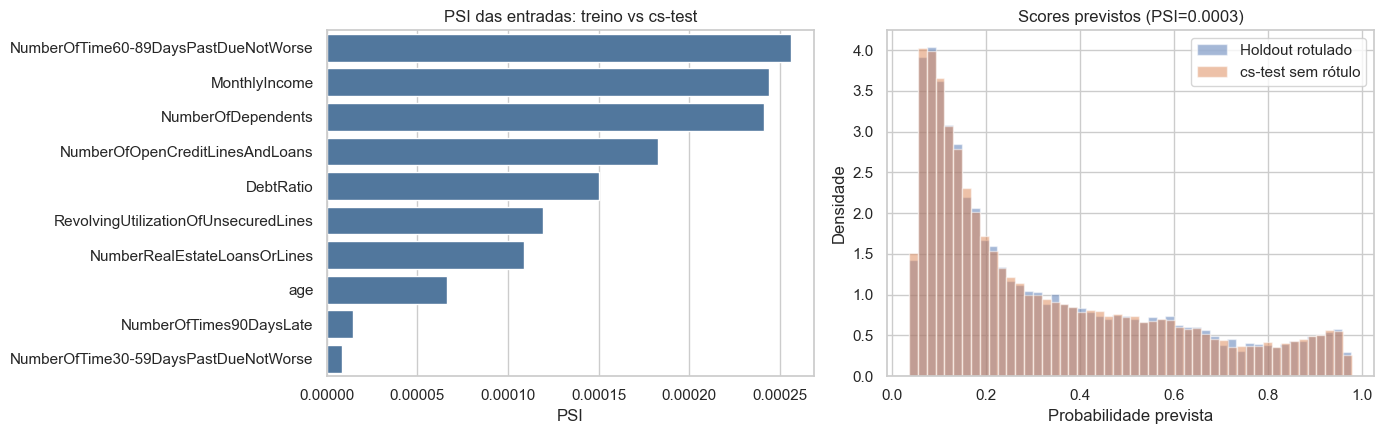

In [11]:
teste_externo = pd.read_csv(DIR_DADOS / 'cs-test.csv')
assert teste_externo[ALVO].isna().all(), 'Alvos inesperadamente presentes; revisar interpretação.'
X_externo = teste_externo[FEATURES]
linhas_diagnostico = []
for f in FEATURES:
    linhas_diagnostico.append({
        'variavel': f,
        'psi_treino_vs_cs_test': psi(X_train[f], X_externo[f]),
        'ausencia_treino': X_train[f].isna().mean(),
        'ausencia_cs_test': X_externo[f].isna().mean(),
    })
diagnostico = pd.DataFrame(linhas_diagnostico).sort_values('psi_treino_vs_cs_test', ascending=False)
scores_externos = prever(X_externo)
psi_scores = psi(p, scores_externos)
display(diagnostico.round(4))
display(pd.DataFrame([
    {'conjunto': 'holdout rotulado', 'n': len(p), 'score_medio': p.mean(),
     'fracao_score_ge_050': (p >= .5).mean()},
    {'conjunto': 'cs-test sem rótulo', 'n': len(scores_externos),
     'score_medio': scores_externos.mean(),
     'fracao_score_ge_050': (scores_externos >= .5).mean()},
]).round(4))
print(f'PSI dos scores (holdout versus cs-test): {psi_scores:.5f}')
print('Brier, AUC, PR-AUC e KS do modelo em cs-test: indisponíveis, pois todos os rótulos são NaN.')

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=diagnostico, y='variavel', x='psi_treino_vs_cs_test', color='#4477aa', ax=eixos[0])
eixos[0].set(title='PSI das entradas: treino vs cs-test', xlabel='PSI', ylabel='')
eixos[1].hist(p, bins=50, density=True, alpha=.5, label='Holdout rotulado')
eixos[1].hist(scores_externos, bins=50, density=True, alpha=.5, label='cs-test sem rótulo')
eixos[1].set(title=f'Scores previstos (PSI={psi_scores:.4f})', xlabel='Probabilidade prevista', ylabel='Densidade')
eixos[1].legend()
plt.tight_layout()
plt.show()

## 6. Exportação e interpretação

`resultados_univariado.csv` guarda todos os cenários, inclusive nível zero. `intensidade` é a força da reponderação; `fracao_nova_ausencia` só vale para falha de medição. `psi_variavel` é o PSI da variável editada; na falha conjunta é o maior PSI das quatro, **não** um PSI multivariado. Compare deltas das quatro métricas com o baseline e veja ESS e prevalência. Qualquer escolha posterior de limite operacional exige custo de negócio, amostra temporal e validação independente; este caderno não impõe um limite arbitrário.

In [12]:
consolidado = pd.concat([resultados_ponderacao, resultados_ausencia], ignore_index=True)
ARQUIVO_RESULTADOS = DIR_SAIDA / 'resultados_univariado.csv'
consolidado.to_csv(ARQUIVO_RESULTADOS, index=False, encoding='utf-8-sig')
print(f'Cenários exportados: {len(consolidado)} | {ARQUIVO_RESULTADOS}')
print('Baseline supervisionado:')
display(pd.DataFrame([base])[CAMPOS_CENTRAIS + ['ap','recall','precision','prevalencia']].round(5))
print('Amplitude observada por variável/direção:')
display(resumo_trajetorias[['variavel','direcao','psi_max','ess_frac_min',
    'maior_queda_auc','maior_queda_prauc_trap','maior_queda_ks_modelo','maior_alta_brier']].round(5))
print('Falha de medição conjunta até 50% de novos faltantes por coluna:')
display(resultados_ausencia.query("familia == 'qualidade_ausencia_4_variaveis'")[
    ['fracao_nova_ausencia','psi_variavel','auc','prauc_trap','ks_modelo','brier']].round(5))

Cenários exportados: 295 | .\results\tables\resultados_univariado.csv
Baseline supervisionado:


,brier,auc,prauc_trap,ks_modelo,ap,recall,precision,prevalencia
0,0.14404,0.86684,0.39599,0.58771,0.39639,0.794,0.21525,0.06667


Amplitude observada por variável/direção:


,variavel,direcao,psi_max,ess_frac_min,maior_queda_auc,maior_queda_prauc_trap,maior_queda_ks_modelo,maior_alta_brier
0,DebtRatio,alta,8.61928,0.10000,-0.02014,0.00000,-0.02651,0.00211
1,DebtRatio,baixa,8.61169,0.10270,0.00000,-0.00179,0.00000,0.00000
2,MonthlyIncome,alta,6.91433,0.12153,-0.01074,-0.05102,-0.00504,0.00000
3,MonthlyIncome,baixa,6.90276,0.12209,-0.02558,-0.05264,-0.03731,0.02376
4,NumberOfDependents,alta,8.70472,0.09873,-0.00009,0.00000,0.00000,0.02993
5,NumberOfDependents,baixa,3.91820,0.60227,0.00000,-0.00632,-0.00009,0.00000
6,NumberOfOpenCreditLinesAndLoans,alta,8.69184,0.09959,-0.05127,-0.08113,-0.07055,0.02737
7,NumberOfOpenCreditLinesAndLoans,baixa,8.47620,0.10030,-0.02623,0.00000,-0.05812,0.11046
8,NumberOfTime30-59DaysPastDueNotWorse,alta,9.06523,0.08873,-0.09566,0.00000,-0.16557,0.25352
9,NumberOfTime30-59DaysPastDueNotWorse,baixa,1.62817,0.83669,-0.03101,-0.14070,-0.05094,0.00000


Falha de medição conjunta até 50% de novos faltantes por coluna:


,fracao_nova_ausencia,psi_variavel,auc,prauc_trap,ks_modelo,brier
44,0.00,0.00000,0.86684,0.39599,0.58771,0.14404
45,0.05,0.78117,0.86189,0.38956,0.57090,0.15410
46,0.10,1.60392,0.85962,0.38731,0.56481,0.16364
47,0.15,2.48867,0.85542,0.38003,0.55414,0.17455
48,0.20,3.42402,0.85129,0.37687,0.54114,0.18532
49,0.25,4.39281,0.84655,0.37335,0.53043,0.19626
50,0.30,5.34225,0.84422,0.37054,0.53176,0.20651
51,0.35,6.30552,0.83940,0.36817,0.52205,0.21722
52,0.40,7.24998,0.83545,0.36217,0.51548,0.22749
53,0.45,8.23303,0.83109,0.35926,0.51624,0.23787
